In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import warnings
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from itertools import permutations, combinations
from collections import defaultdict
from joblib import Parallel, delayed
from tqdm import tqdm
from pyEDM import *

## Load Data

For gap filling, you could probably use time series from different conservation units or different salmon species. Here I just used time series for species = "Chum", but it is possible there's some interaction between different species that would contain information.

In [2]:
data = pd.read_csv('dataset2_spawner_surveys.csv')

# Filter for species == 'Chum' and 7 Conservation Units
cus = ['Bute Inlet', 'Georgia Strait', 'Howe Sound-Burrard Inlet', 'Loughborough', 'Northeast Vancouver Island', 
       'Southern Coastal Streams', 'Upper Knight']
data = data[(data.species_name=='Chum') & (data.cu_name_pse.isin(cus))]

# Replace negative values with NaN
data.loc[data['stream_observed_count'] < 0, 'stream_observed_count'] = np.nan

# Create a dictionary where keys are 'cu_name_pse' and values are the sub-dataframes
cu_dict = {name: group for name, group in data.groupby('cu_name_pse')}

stream_dict = {(cu, stream): group for (cu, stream), group in data.groupby(['cu_name_pse', 'stream_name_pse'])}

# Define the full range of years you want to cover
all_years = np.arange(data['year'].min(), data['year'].max() + 1)

# Process each time series
for key in list(stream_dict.keys()):

    df_stream = stream_dict[key]
    
    # Sort and keep relevant columns
    df_stream = df_stream[['year', 'stream_observed_count']].sort_values(by='year')

    # Handle duplicates
    df_stream = df_stream.groupby('year').mean().reset_index()

    # Square-root, then min-max normalize
    df_stream['stream_observed_count'] = np.sqrt(df_stream['stream_observed_count'])

    # Reindex to include all years
    df_stream = df_stream.set_index('year').reindex(all_years).reset_index()

    # Min-max normalize 
    obs = df_stream['stream_observed_count']
    if obs.notna().any():
        df_stream['stream_observed_count'] = (obs - obs.min()) / (obs.max() - obs.min())
    
    # Update the dictionary
    stream_dict[key] = df_stream

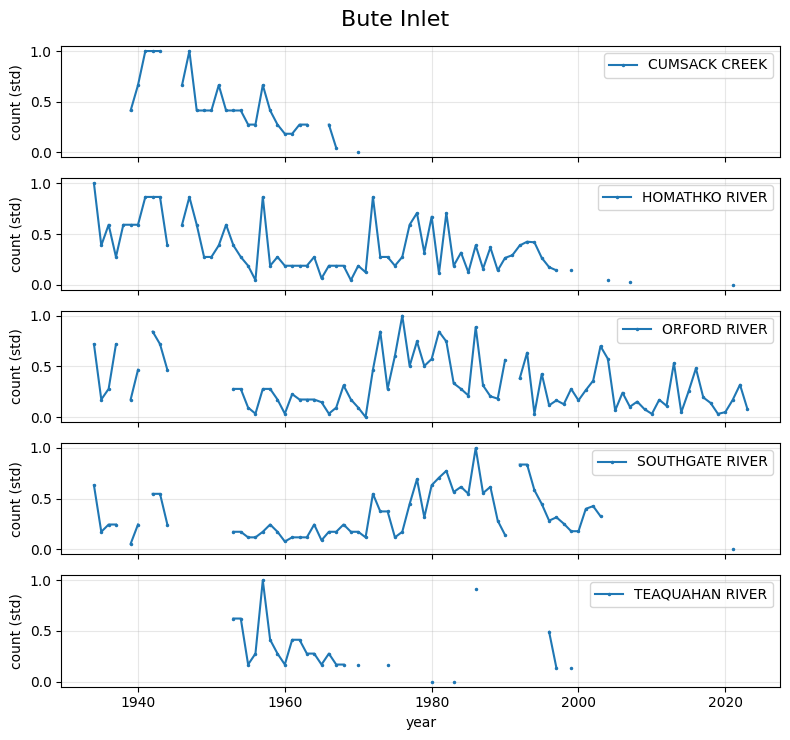

In [3]:
def plot_cu_streams(cu_name, stream_dict):
    streams_in_cu = [k for k in stream_dict.keys() if k[0] == cu_name]
    n_streams = len(streams_in_cu)
    
    # Create a figure with one subplot per stream
    fig, axes = plt.subplots(nrows=n_streams, ncols=1, figsize=(8, 1.5 * n_streams), sharex=True)
    
    # If there is only 1 stream, 'axes' isn't a list, so we wrap it
    if n_streams == 1:
        axes = [axes]
    
    for ax, key in zip(axes, streams_in_cu):
        data = stream_dict[key]
        stream_name = key[1]
        
        # Plot the data
        ax.plot(data['year'], data['stream_observed_count'], marker='.', markersize=3, label=stream_name)
        
        # Formatting
        ax.set_ylabel("count (std)")
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.3)
    
    plt.xlabel("year")
    plt.suptitle(f"{cu_name}", fontsize=16)
    plt.tight_layout()
    plt.show()

# Example usage:
plot_cu_streams('Bute Inlet', stream_dict)

## See if time series are correlated

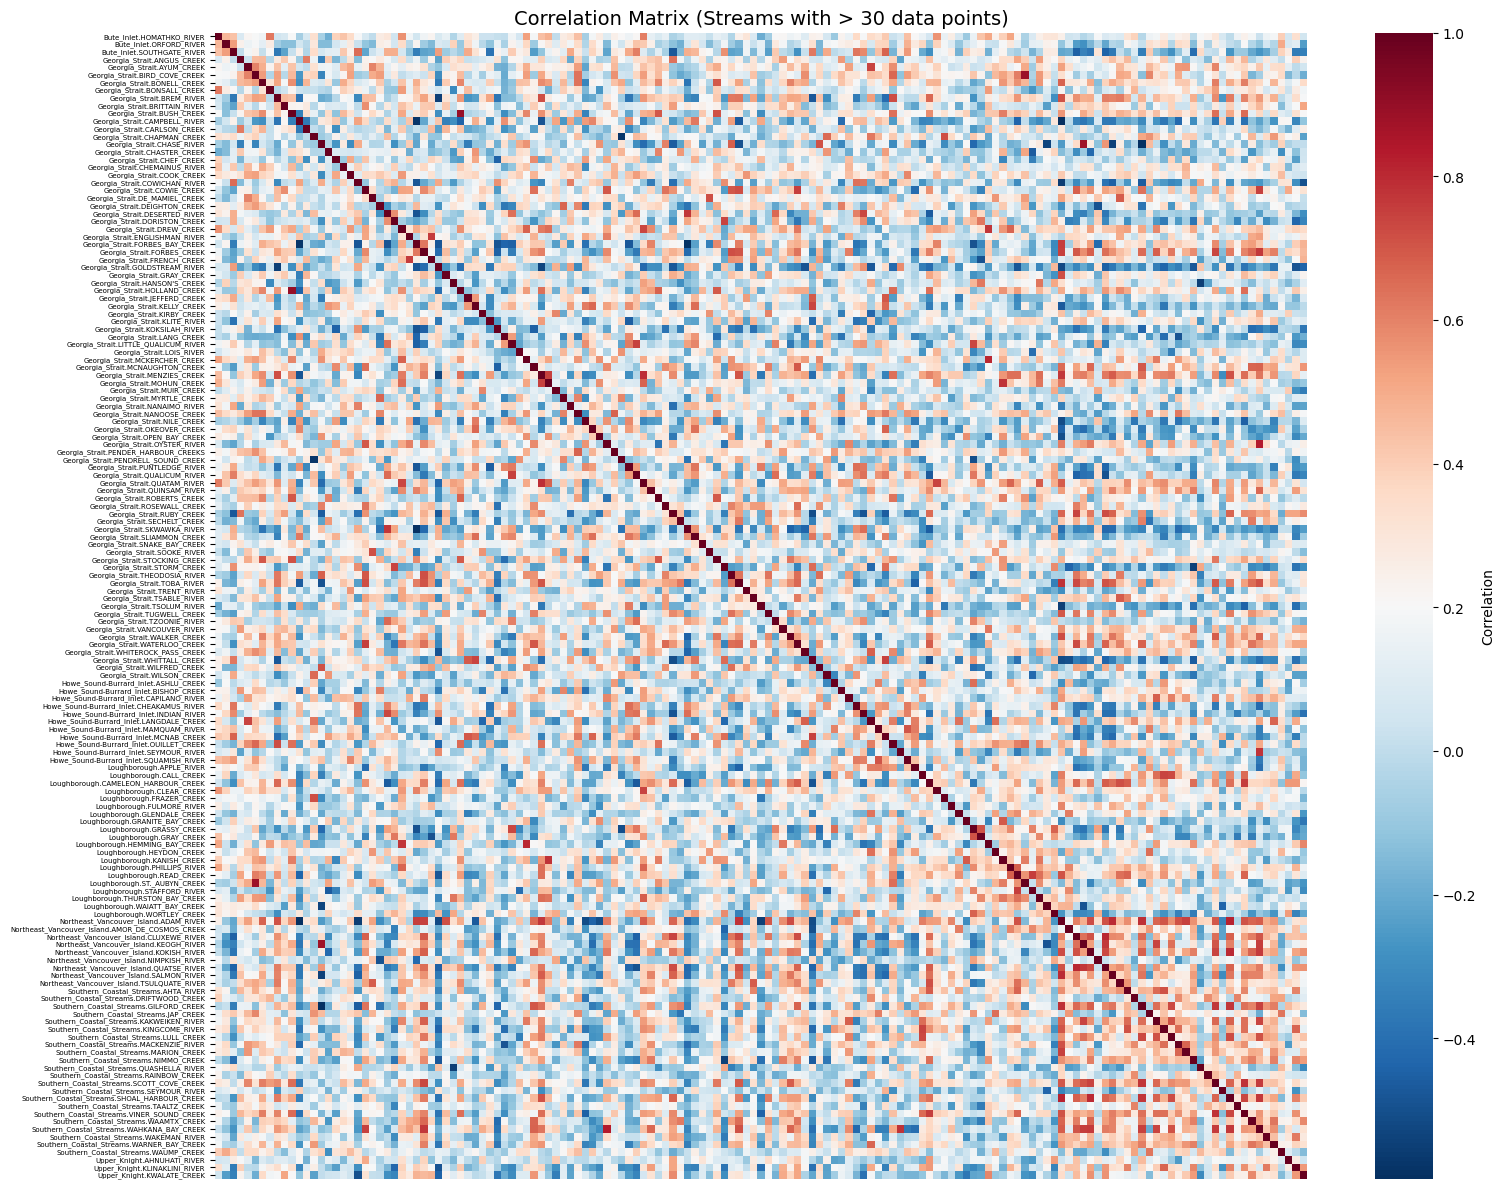

In [4]:
# First step: correlation

# Create wide_df
series_list = []
for key, df_stream in stream_dict.items():
    s = pd.Series(data=df_stream['stream_observed_count'].values, index=df_stream['year'], name=key)
    series_list.append(s)
wide_df = pd.concat(series_list, axis=1)

# Flatten column names
wide_df.columns = ['.'.join(col).strip() for col in wide_df.columns.values]
wide_df.columns = [col.replace(' ', '_') for col in wide_df.columns]

# Identify columns with more than 30 non-NaN values
min_data_points = 30
valid_cols = wide_df.columns[wide_df.count() > min_data_points]
filtered_wide_df = wide_df[valid_cols]
filtered_corr_matrix = filtered_wide_df.corr()

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(16,12))
ax = sns.heatmap(
    filtered_corr_matrix, 
    cmap='RdBu_r',  
    xticklabels=False, 
    yticklabels=True,
    cbar_kws={'label': 'Correlation'}
)
ax.tick_params(axis='y', labelsize=5) 
plt.title(f'Correlation Matrix (Streams with > {min_data_points} data points)', fontsize=14)
plt.tight_layout()
plt.show()

It seems like the time series from each conservation unit are not highly correlated with one other (except maybe in Northeast Vancouver Island).

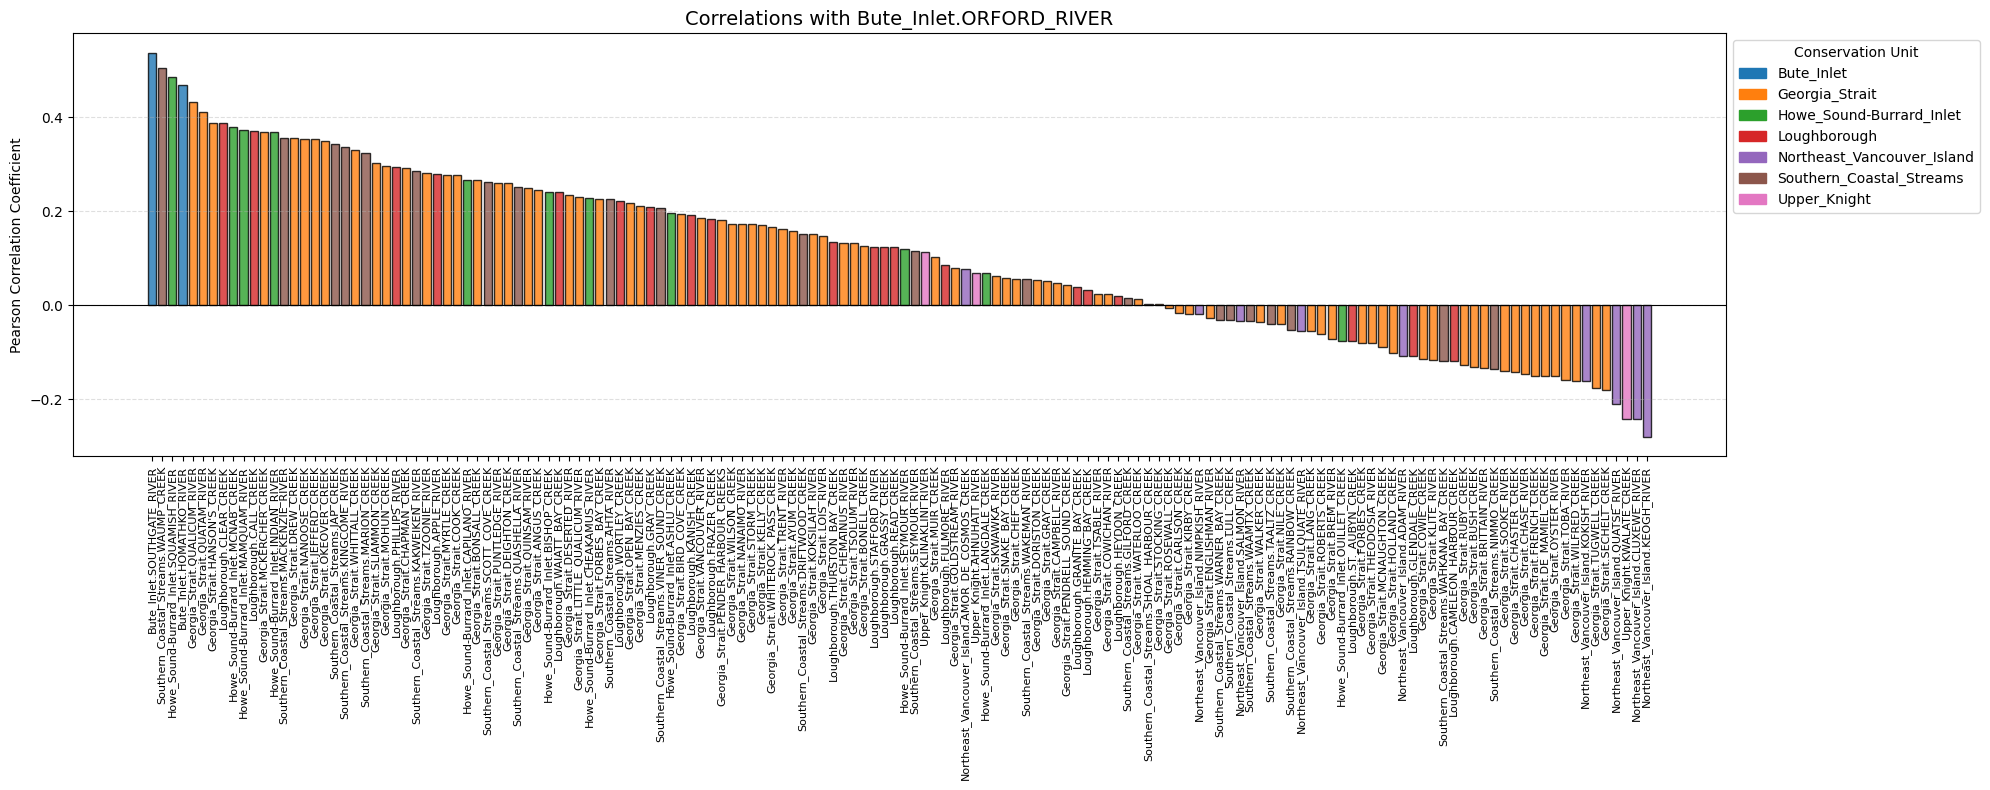

In [5]:
# Visualize correlations of one stream with the others
target = 'Bute_Inlet.ORFORD_RIVER'

# Extract and sort (positive to negative)
corrs_for_target = filtered_corr_matrix[target].sort_values(ascending=False)
corrs_for_target = corrs_for_target.drop(labels=[target])

# Assign colors to different conservation units (CUs)
unique_cus = sorted(list(set([k.split('.')[0] for k in corrs_for_target.index])))
cmap = plt.get_cmap('tab10')
cu_color_map = {cu: cmap(i % 10) for i, cu in enumerate(unique_cus)}

# Prepare data for plotting
labels = [k for k in corrs_for_target.index]
bar_colors = [cu_color_map[k.split('.')[0]] for k in corrs_for_target.index]

# Create the Plot
fig, ax = plt.subplots(figsize=(20, 8))
bars = ax.bar(labels, corrs_for_target.values, color=bar_colors, edgecolor='black', alpha=0.8)

# Add the Legend
legend_patches = [mpatches.Patch(color=cu_color_map[cu], label=cu) for cu in unique_cus]
ax.legend(handles=legend_patches, title="Conservation Unit", bbox_to_anchor=(1.00, 1), loc='upper left')

# Formatting
ax.axhline(0, color='black', linewidth=0.8) # Horizontal line at 0 for vertical bars
ax.set_ylabel('Pearson Correlation Coefficient')
ax.set_title(f'Correlations with {target}', fontsize=14)

# Rotate labels so they don't overlap
plt.xticks(rotation=90, fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

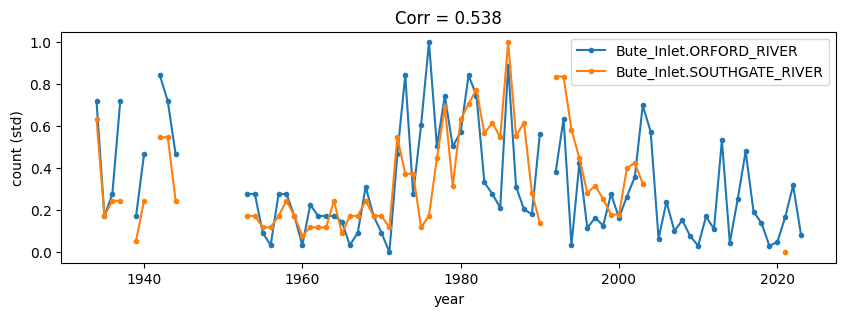

In [6]:
# Compare the time series of two streams
stream1 = 'Bute_Inlet.ORFORD_RIVER'
stream2 = 'Bute_Inlet.SOUTHGATE_RIVER'

# Compute correlation
corr = wide_df[[stream1, stream2]].corr().iloc[0,1]

# Plot the two time series and their correlation
fig, ax = plt.subplots(figsize=(10, 3))
wide_df.plot(ax=ax, y=stream1, marker='.', label=stream1)
wide_df.plot(ax=ax, y=stream2, marker='.', label=stream2)
ax.set_title(f'Corr = {corr:.3f}')
plt.legend()
plt.ylabel("count (std)")
plt.show()

## Now get CCM matrix

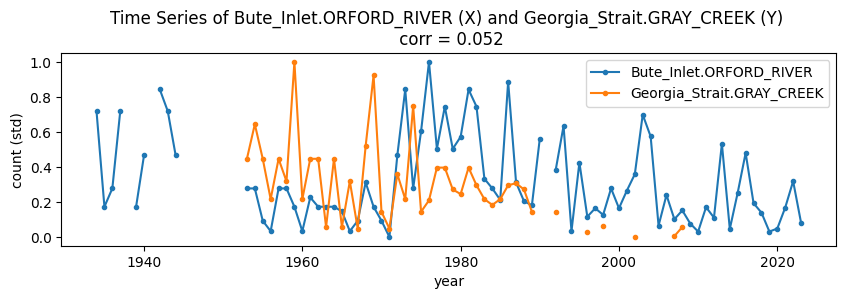

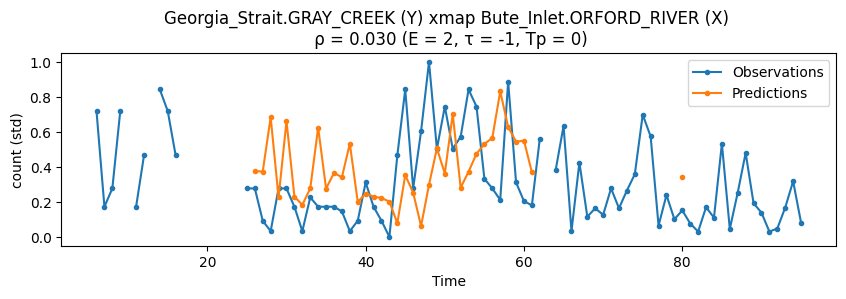

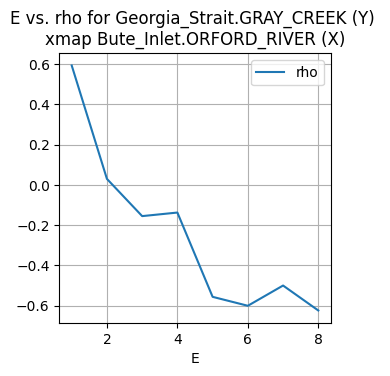

In [7]:
# First, we want to find overall which variables are causal (make a CCM heatmap)

def compute_xmap_pair(dataFrame, columns, target, lib, pred, E, tau, Tp, exclusionRadius, noTime=False):
    """
    Compute the cross-mapping from the columns to the target, handling missing values with the validLib parameter.
    """
    # Set up validLib parameter for NaN handling (validLib is where embedding vector AND target+Tp is not NaN)
    embedding = Embed(dataFrame, E=E, tau=tau, columns=columns)
    valid_embed = embedding.notna().all(axis=1)
    valid_target = dataFrame[target].shift(-Tp).notna()
    validLib = valid_embed & valid_target

    # Use exclusionRadius = E * tau
    if exclusionRadius == True:
        exclusionRadius = E * np.abs(tau)
    
    # Cross-map using the Simplex function (if there are enough valid library vectors)
    points_removed_by_radius = (2 * exclusionRadius) + 1
    if validLib.sum() > (E + 1) + points_removed_by_radius:
        result = Simplex(dataFrame=dataFrame, columns=columns, target=target, lib=lib, pred=pred, E=E, tau=tau, Tp=Tp,
                         exclusionRadius=exclusionRadius, validLib=validLib, noTime=noTime)
    else:
        result = None
    return result

def xmap_embed_dimension(dataFrame, columns, target, lib, pred, maxE, tau, Tp, exclusionRadius, noTime=False):
    """
    Run cross-mapping X (target) <-- Y (columns) for a range of E's (Tp = 0, tau = -1). 
    This looks for evidence of a causal relationship X => Y
    Returns:
    embed_dimension: DataFrame 
        E vs. rho for the interaction
    pred_masks: dict
        Keys: E 
        Values: boolean Series indicating where predictions exist
    """
    embed_dimension = []
    for E in range(1, maxE + 1):
        result = compute_xmap_pair(dataFrame=dataFrame, columns=columns, target=target, lib=lib, pred=pred, E=E, tau=tau, Tp=Tp,
                                   exclusionRadius=exclusionRadius, noTime=noTime)
        if result is None or result['Predictions'].isna().all():
            rho = np.nan
        else:
            rho = result[['Observations', 'Predictions']].corr().iloc[0,1]
        embed_dimension.append({'E': E, 'rho': rho})
    embed_dimension = pd.DataFrame(embed_dimension)
    return embed_dimension


## Cross-mapping example

# We use convergent cross-mapping to determine if X drives Y.
X = 'Bute_Inlet.ORFORD_RIVER'     # Variable X (The cause / driver)
Y = 'Georgia_Strait.GRAY_CREEK'   # Variable Y (The effect / response)

# Define interaction pair (cause, effect)
interaction = (X,Y)

# Plot interaction
fig, ax = plt.subplots(figsize=(10,2.5))
filtered_wide_df.plot(y=[interaction[0], interaction[1]], ax=ax, style='.-')
corr = filtered_wide_df[[interaction[0], interaction[1]]].corr().iloc[0,1]
plt.title(f'Time Series of {interaction[0]} (X) and {interaction[1]} (Y) \n corr = {corr:.3f}')
plt.ylabel('count (std)')
plt.show()

lib = f'1 {len(filtered_wide_df)}'
pred = lib
E = 2
tau = -1
Tp = 0
exclusionRadius = True

# Compute xmap pair
result = compute_xmap_pair(filtered_wide_df, columns=interaction[1], target=interaction[0], lib=lib, pred=pred, E=E, tau=tau, Tp=Tp, 
                           exclusionRadius=True, noTime=True)

corr = result[['Observations', 'Predictions']].corr().iloc[0,1]
result.plot(x='Time', y=['Observations', 'Predictions'], figsize=(10,2.5), style='.-')
plt.title(f'{interaction[1]} (Y) xmap {interaction[0]} (X) \n ρ = {corr:.3f} (E = {E}, τ = {tau}, Tp = {Tp})')
plt.ylabel('count (std)')
plt.show()

# Embed dimension
maxE = 10
embed_dimension = xmap_embed_dimension(filtered_wide_df, columns=interaction[1], target=interaction[0], lib=lib ,pred=pred, maxE=maxE, tau=tau, Tp=Tp,
                                       exclusionRadius=True, noTime=True)

embed_dimension.plot(x='E', y='rho', figsize=(3.5,3.5))
plt.title(f'E vs. rho for {interaction[1]} (Y) \nxmap {interaction[0]} (X)')
plt.grid(True)
plt.show()

In [8]:
# Get cross-map matrix between all pairs of species. Not testing for convergence here, but you could do that if you wanted to establish
# causality more robustly.

ts_data = filtered_wide_df.copy()

# Define parameters
lib = f'1 {len(ts_data)}'
pred = lib
maxE = 10                # maximum of the range of E's to try for cross-mapping (1:maxE)
tau = -1                 # choose one tau
Tp = 0                   # choose one Tp
exclusionRadius = True   # will use exclusionRadius = E * tau (not sure if strictly necessary for cross-mapping or not)

# Get list of all possible interactions X => Y between pairs of variables
all_interactions = list(permutations(ts_data.columns,2))
all_xmap_pairs = {}

def process_interaction(interaction, dataFrame, maxE, tau, Tp, exclusionRadius):
    '''Return cross-mapping results for an interaction pair X => Y over a range of E's.'''
    E_vs_rho = xmap_embed_dimension(dataFrame, columns=interaction[1], target=interaction[0], lib=lib, pred=pred, maxE=maxE, tau=tau, Tp=Tp,
                                    exclusionRadius=exclusionRadius, noTime=True)
    return interaction, {
        'driver (X)': interaction[0],
        'driven (Y)': interaction[1],
        'tau': tau,
        'Tp': Tp,
        'E_vs_rho': E_vs_rho,
    }

results = Parallel(n_jobs=-1)(delayed(process_interaction)(inter, ts_data, maxE, tau, Tp, exclusionRadius) for inter in tqdm(all_interactions))

# Convert list of tuples back into the all_xmap_pairs dictionary
all_xmap_pairs = dict(results)

100%|████████████████████████████████████| 22052/22052 [00:57<00:00, 382.22it/s]


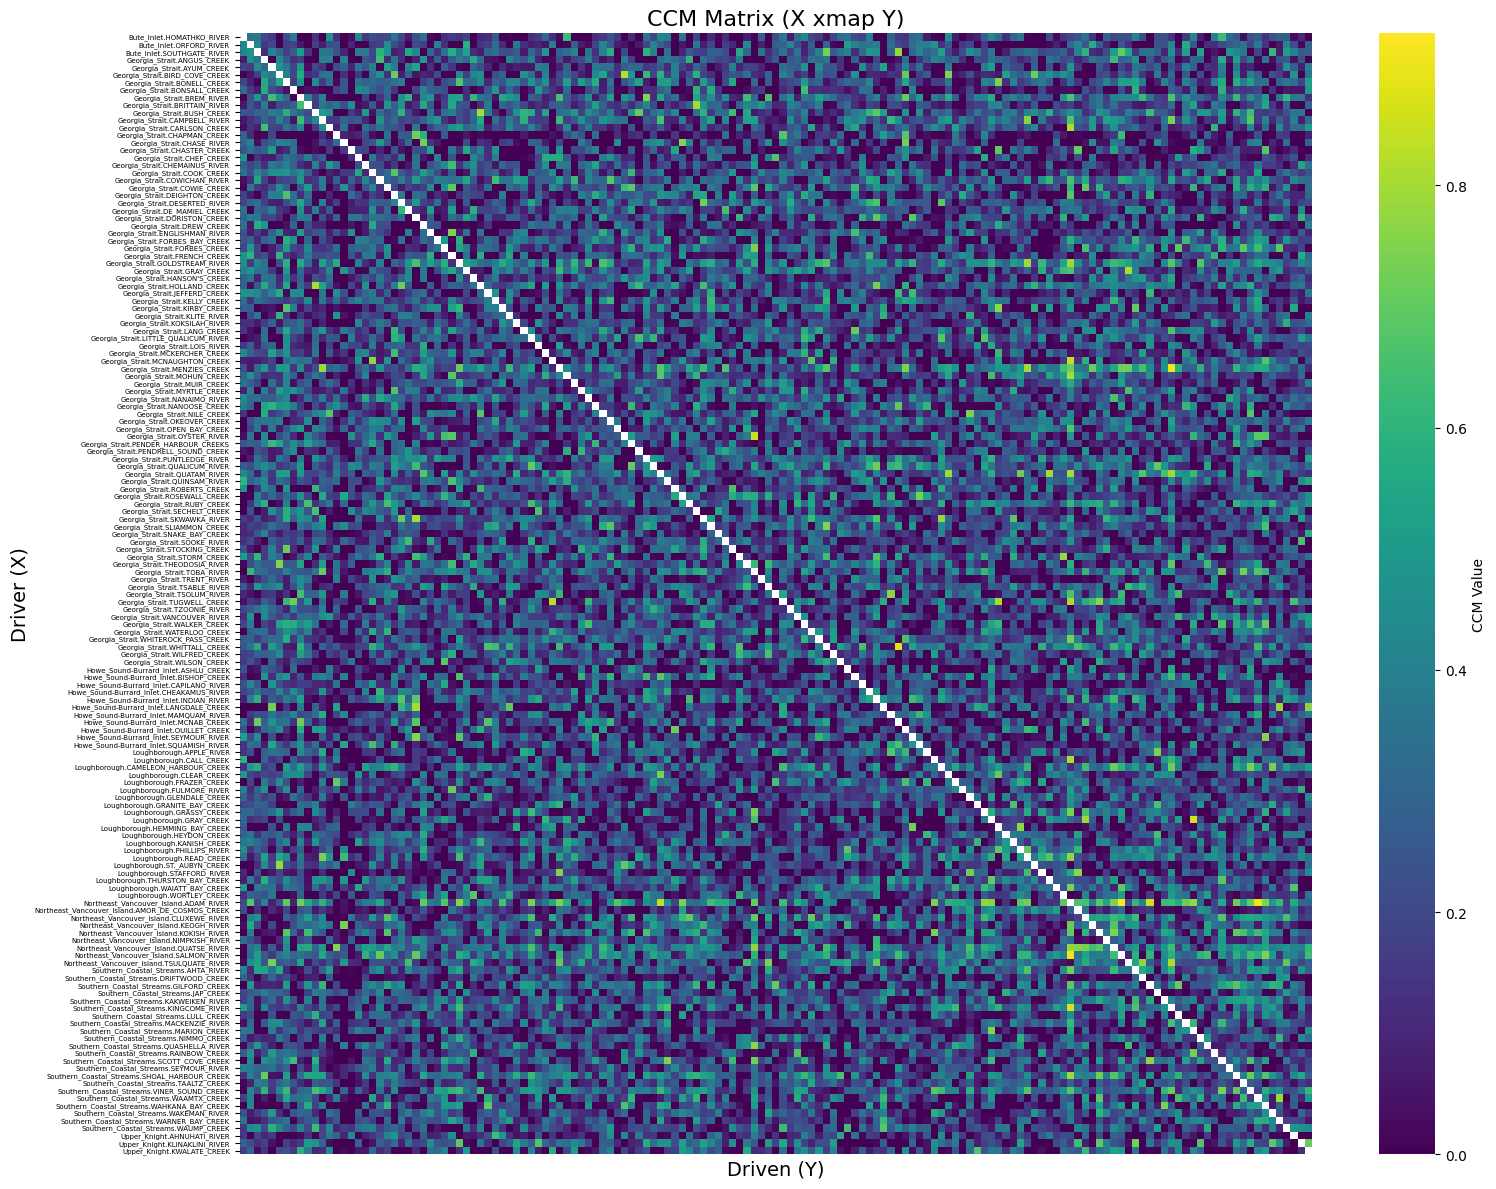

In [9]:
# Plot CCM matrix

# Flatten the results into a DataFrame
ccm_list = []
for (driver, driven), result in all_xmap_pairs.items():
    # Find the max rho across all E values for this specific pair
    max_rho = result['E_vs_rho']['rho'].max()
    ccm_list.append({'driver': driver,'driven': driven,'rho': max_rho})
ccm_df = pd.DataFrame(ccm_list)

# Pivot the data into a square matrix, with Index (y-axis) = Driver, Columns (x-axis) = Driven
ccm_matrix = ccm_df.pivot(index='driver', columns='driven', values='rho')

# Ensure the order of indices matches the columns for a clean diagonal
ccm_matrix = ccm_matrix.reindex(index=ccm_matrix.columns)

# CCM values below 0 are not meaningful
ccm_matrix[ccm_matrix < 0] = 0

fig, ax = plt.subplots(figsize=(16,12))
ax = sns.heatmap(
    ccm_matrix, 
    cmap='viridis',  
    xticklabels=False, 
    yticklabels=True,
    cbar_kws={'label': 'CCM Value'}
)
ax.tick_params(axis='y', labelsize=5) 
plt.title('CCM Matrix (X xmap Y)', fontsize=16)
plt.ylabel('Driver (X)', fontsize=14)
plt.xlabel('Driven (Y)', fontsize=14)
plt.tight_layout()
plt.show()

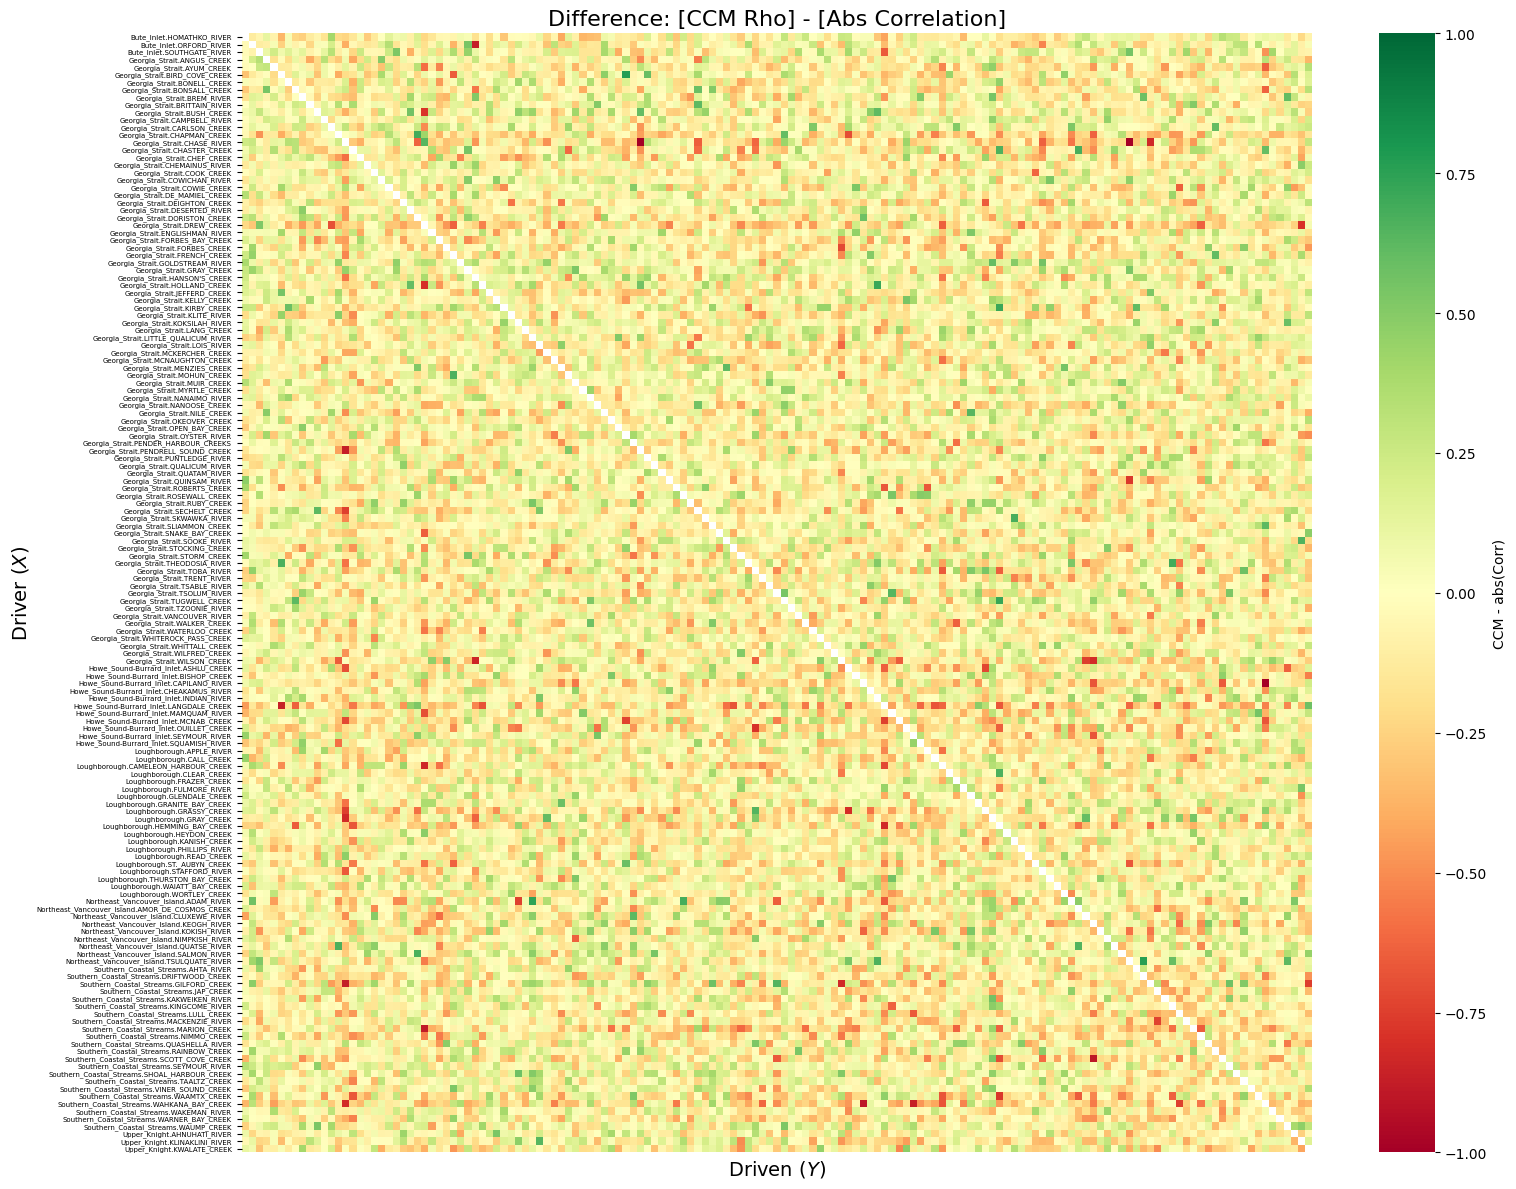

In [10]:
# Compare CCM vs. correlation strength
abs_corr = filtered_corr_matrix.abs()

# Pivot CCM and force it to match the correlation matrix alignment
ccm_matrix = ccm_df.pivot(index='driver', columns='driven', values='rho')

# Reindex both rows and columns to match the correlation matrix exactly
ccm_matrix_aligned = ccm_matrix.reindex(index=abs_corr.index, columns=abs_corr.columns)

# Calculate the difference
diff_matrix = ccm_matrix_aligned - abs_corr

fig, ax = plt.subplots(figsize=(16,12))
ax = sns.heatmap(
    diff_matrix, 
    cmap='RdYlGn', 
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False, 
    yticklabels=True,
    cbar_kws={'label': 'CCM - abs(Corr)'}
)
ax.tick_params(axis='y', labelsize=5) 
plt.title('Difference: [CCM Rho] - [Abs Correlation]', fontsize=16)
plt.ylabel('Driver ($X$)', fontsize=14)
plt.xlabel('Driven ($Y$)', fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
def get_block(data, columns, target, num_lags, tau):
    ''' Get a dataframe with one copy of the target variable and the specified number (num_lags, tau) of lagged predictor variables. 
        Uses both forward and backward lags of the predictor variables (so we can get information from interactions in either direction). '''
    backward_lags = Embed(dataFrame=data, columns=columns, E=num_lags, tau=tau)
    forward_lags  = Embed(dataFrame=data, columns=columns, E=num_lags, tau=-1*tau)
    
    block = pd.concat([backward_lags, forward_lags], axis=1)
    block.insert(0, target, data[target])

    # Remove all columns that contain the string "(t+0)" -- same as (t-0)
    block = block.loc[:, ~block.columns.str.contains(r'\(t\+0\)')]
    
    return block

def get_all_causal_partners(lookup, target):
    '''Return all relevant CCM interactions involving a target variable, sorted by best to worst rho value.'''
    # Collect all interactions involving the target
    relevant = lookup.get(target, [])
    
    # Extract the best E and rho
    ## Combine all small E vs. rho tables into one big DataFrame and sort by rho value
    all_data = pd.concat([r['E_vs_rho'].assign(driver=r['driver (X)'], driven=r['driven (Y)']) for r in relevant], ignore_index=True)
    all_data = all_data.dropna(subset=['rho']).sort_values('rho')
    
    ## Group by the interaction and take the best (last) row
    summary = (all_data.groupby(['driver', 'driven'], as_index=False).last().rename(columns={'E': 'best_E', 'rho': 'best_rho'}))
    
    ## Final sort for output
    summary = summary.sort_values(by='best_rho', ascending=False).reset_index(drop=True)
    
    return summary

# Lookup dictionary for finding CCM interactions involving a target variable
lookup = defaultdict(list)
for res in all_xmap_pairs.values():
    lookup[res['driver (X)']].append(res)
    lookup[res['driven (Y)']].append(res)

## MVCM Gap Filling

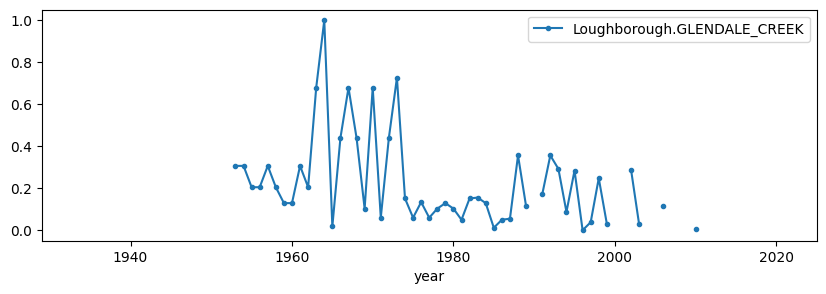

In [12]:
# Goal: fill gaps in this time series

target = 'Loughborough.GLENDALE_CREEK' #'Northeast_Vancouver_Island.ADAM_RIVER' #'Bute_Inlet.ORFORD_RIVER'

fig, ax = plt.subplots(figsize=(10,3))
filtered_wide_df.plot(y=target, marker='.', label=target, ax=ax)
ax.set_xlim(data['year'].min(), data['year'].max() + 1)
plt.legend()
plt.show()

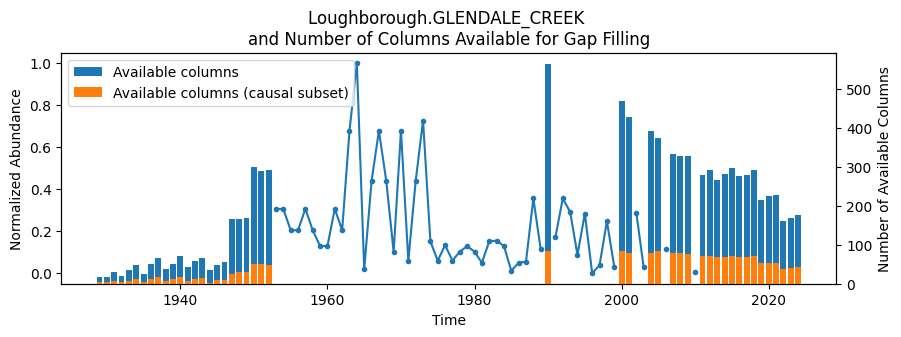

Number of columns available for gap filling (causal subset)


year
1929     4
1930     4
1931     6
1932     4
1933     8
1934    11
1935     4
1936    13
1937    16
1938     6
1939    13
1940    16
1941     6
1942    13
1943    14
1944     2
1945     9
1946    10
1947    26
1948    30
1949    29
1950    51
1951    50
1952    49
1990    85
2000    85
2001    80
2004    80
2005    84
2007    78
2008    79
2009    76
2011    72
2012    71
2013    68
2014    69
2015    72
2016    69
2017    68
2018    71
2019    54
2020    53
2021    54
2022    37
2023    40
2024    42
dtype: int64

In [13]:
# Set up MVCM parameters. We want to find out how many time series we have available to fill each gap in our target time series.
# Goal: have at least one time series available to fill each gap, while also minimizing computation time and still making good predictions.
## num_lags : number of lags of each predictor time series to consider
## tau : time lag of lagged columns
## n_partners : number of causal partners to consider for embeddings (you could also use a rho cutoff)

num_lags = 3
tau = -3
n_partners = 25

# Find number of time series available to fill each gap in the target time series
missing_mask = ts_data[target].isna()
gap_years = ts_data.index[missing_mask]

# Get the full block (all variables)
block_full = get_block(ts_data, ts_data.columns.tolist(), target, num_lags, tau)
n_full = block_full.loc[gap_years].notna().sum(axis=1)

# Get the block using only the subset of causal variables
summary = get_all_causal_partners(lookup, target)
all_potential = summary[['driver', 'driven']].stack()
partners = [v for v in all_potential.unique() if v != target][:n_partners]

block_subset = get_block(ts_data, partners, target, num_lags, tau)
n_subset = block_subset.loc[gap_years].notna().sum(axis=1)

# Visualize number of time series available to fill each gap
fig, ax = plt.subplots(figsize=(10,3))
ts_data[target].plot(ax=ax, marker='.')
ax.set_title(f'{target} \nand Number of Columns Available for Gap Filling')
ax.set_ylabel('Normalized Abundance')
ax2 = ax.twinx()
ax2.bar(n_full.index,n_full.values,label='Available columns')
ax2.bar(n_subset.index, n_subset.values, label='Available columns (causal subset)')
ax2.set_ylabel('Number of Available Columns')
ax.set_xlabel('Time')
plt.legend()
plt.show()
print('Number of columns available for gap filling (causal subset)')
display(n_subset)

In [14]:
# Get list of columns from the block that can fill each gap year
valid_mask = block_subset.loc[gap_years].notna()

# Remove the target column from potential predictors in the block
candidate_vars = [c for c in block_subset.columns if c != target]

# Build a dictionary of candidate columns per year. Key: year, value: List of available column names for that year
available_per_year = {year: valid_mask.columns[valid_mask.loc[year]].tolist() for year in gap_years}

# Embedding dimensions to consider
E_range = [2, 3]

# Create embeddings by choosing E random columns from the block
embeddings_by_year = {}
for year in gap_years:
    year_candidates = [c for c in available_per_year[year] if c != target]

    # Generate all possible combinations of size E from the columns available for this gap year
    year_embeddings = []
    for E in E_range:
        combos = list(combinations(year_candidates, E))
        year_embeddings.extend(combos)
    embeddings_by_year[year] = year_embeddings

# Find the global set of unique embeddings needed
all_unique_embeddings = sorted(list(set(emb for year_embs in embeddings_by_year.values() for emb in year_embs)))

# How many embeddings per year
counts = {key: len(value) for key, value in embeddings_by_year.items()}
print(f'Number of embeddings available to fill each gap:')
display(counts)

Number of embeddings available to fill each gap:


{1929: 10,
 1930: 10,
 1931: 35,
 1932: 10,
 1933: 84,
 1934: 220,
 1935: 10,
 1936: 364,
 1937: 680,
 1938: 35,
 1939: 364,
 1940: 680,
 1941: 35,
 1942: 364,
 1943: 455,
 1944: 1,
 1945: 120,
 1946: 165,
 1947: 2925,
 1948: 4495,
 1949: 4060,
 1950: 22100,
 1951: 20825,
 1952: 19600,
 1990: 102340,
 2000: 102340,
 2001: 85320,
 2004: 85320,
 2005: 98770,
 2007: 79079,
 2008: 82160,
 2009: 73150,
 2011: 62196,
 2012: 59640,
 2013: 52394,
 2014: 54740,
 2015: 62196,
 2016: 54740,
 2017: 52394,
 2018: 59640,
 2019: 26235,
 2020: 24804,
 2021: 26235,
 2022: 8436,
 2023: 10660,
 2024: 12341}

In [15]:
def compute_xmap_pair_smap(block, columns, target, lib, pred, Tp, theta, embedded=False, noTime=False):
    """
    Compute the cross-mapping from the embedded columns to the target variable using S-Map.
    Input: 
    block    : dataFrame with target time series and lagged predictor time series
    columns  : list of embedding column names
    target   : target variable name
    lib/pred : training and testing sets
    Tp       : prediction horizon
    theta    : S-map locality parameter
    """
    if embedded == False:
        raise ValueError('This function was written to work with embedded = True')
    
    # Cross-map using the SMap function
    try:
        result = SMap(dataFrame=block, columns=columns, target=target, lib=lib, pred=pred, Tp=Tp, theta=theta, noTime=noTime, embedded=embedded)
    
        preds = result['predictions']
        # pred_mask = preds['Predictions'].notna()
        not_na = preds['Predictions'].notna()
        pred_mask = pd.DataFrame({'Time': preds['Time'], 'Mask': not_na})
        
        rho = preds[['Observations', 'Predictions']].corr().iloc[0,1]
    
        return tuple(columns), rho, pred_mask, preds
    except:
        # Failed embedding
        failed_mask = pd.DataFrame({
            'Time': block.iloc[:, 0], 
            'Mask': [False] * len(block)
        })
        return tuple(columns), np.nan, failed_mask, None
    
def get_xmap_results_smap(block, target, embeddings, Tp, theta, lib, pred, embedded=False, noTime=False, progress_bar=False):
    '''Get SMap results for a list of embeddings.'''

    # Compute S-map results for each embedding
    n_tasks = len(embeddings)
    results = Parallel(n_jobs=-1)(
        delayed(compute_xmap_pair_smap)(
            block, list(embedding), target, lib, pred, Tp, theta, embedded, noTime
        ) 
        for embedding in tqdm(
            embeddings, 
            total=n_tasks, 
            desc=f"Running S-map θ={theta}", 
            disable=not progress_bar  # Only shows if progress_bar == True
        )
    )
    
    # Build outputs
    embedding_results = {}
    summary_rows = []
    for embedding, rho, pred_mask, preds in results:
        embedding_results[embedding] = {
            "rho": rho, 
            "pred_mask": pred_mask, 
            "predictions": preds}

        # Count number of predictions
        if pred_mask is not None:
            n_valid = pred_mask['Mask'].sum()
        else:
            n_valid = 0
            
        summary_rows.append({
            "embedding": embedding,
            "E": len(embedding),
            "rho": rho,
            "n_pred": n_valid #pred_mask.sum() if pred_mask is not None else 0
        })

    summary = (pd.DataFrame(summary_rows).sort_values("rho", ascending=False).reset_index(drop=True))
    return summary, embedding_results

theta = 5
Tp = 0
lib = f'1 {len(ts_data)}'
pred = f'1 {len(ts_data)}'
embedded = True
noTime = False

summary, embedding_results = get_xmap_results_smap(block_subset.reset_index(), target, all_unique_embeddings, Tp, theta, lib, pred, embedded, 
                                                   noTime, progress_bar=True)
display(summary.dropna())

Running S-map: 100%|██████████████████| 258532/258532 [01:43<00:00, 2492.67it/s]


time to compute 258532 embeddings: 113.07066011428833 seconds


,embedding,E,rho,n_pred
0,"(Georgia_Strait.KLITE_RIVER(t-6), Georgia_Stra...",3,0.999873,7
1,"(Georgia_Strait.TOBA_RIVER(t-0), Northeast_Van...",3,0.997488,6
2,(Northeast_Vancouver_Island.AMOR_DE_COSMOS_CRE...,3,0.993901,13
3,"(Loughborough.PHILLIPS_RIVER(t-0), Northeast_V...",3,0.992939,13
4,"(Northeast_Vancouver_Island.QUATSE_RIVER(t-6),...",3,0.991275,8
...,...,...,...,...
258246,"(Loughborough.STAFFORD_RIVER(t+6), Loughboroug...",3,-0.936368,15
258247,"(Georgia_Strait.KLITE_RIVER(t-3), Loughborough...",3,-0.936479,7
258248,"(Georgia_Strait.KLITE_RIVER(t-3), Georgia_Stra...",3,-0.938849,8
258249,"(Georgia_Strait.TOBA_RIVER(t-6), Loughborough....",3,-0.944530,13


In [16]:
# Filter for embeddings that made predictions in a given year
target_year = 1940

# Filter the summary
filtered_summary = summary[
    summary['embedding'].apply(lambda x: 
        embedding_results[x]['pred_mask'].loc[
            embedding_results[x]['pred_mask']['Time'] == target_year, 'Mask'
        ].any()
    )
]
display(filtered_summary)

,embedding,E,rho,n_pred
59,"(Loughborough.STAFFORD_RIVER(t-0), Loughboroug...",2,0.889603,24
221,"(Loughborough.STAFFORD_RIVER(t-0), Loughboroug...",3,0.817119,14
1818,"(Loughborough.STAFFORD_RIVER(t-3), Loughboroug...",3,0.701711,26
2284,"(Loughborough.GRAY_CREEK(t-0), Georgia_Strait....",2,0.687148,34
2740,"(Georgia_Strait.MENZIES_CREEK(t-0), Loughborou...",3,0.675178,28
...,...,...,...,...
256755,"(Loughborough.STAFFORD_RIVER(t-3), Loughboroug...",3,-0.527215,24
256773,"(Loughborough.STAFFORD_RIVER(t-3), Loughboroug...",3,-0.528205,15
257358,"(Loughborough.STAFFORD_RIVER(t+3), Loughboroug...",3,-0.583044,24
257755,"(Loughborough.GRAY_CREEK(t-3), Loughborough.ST...",3,-0.648323,18


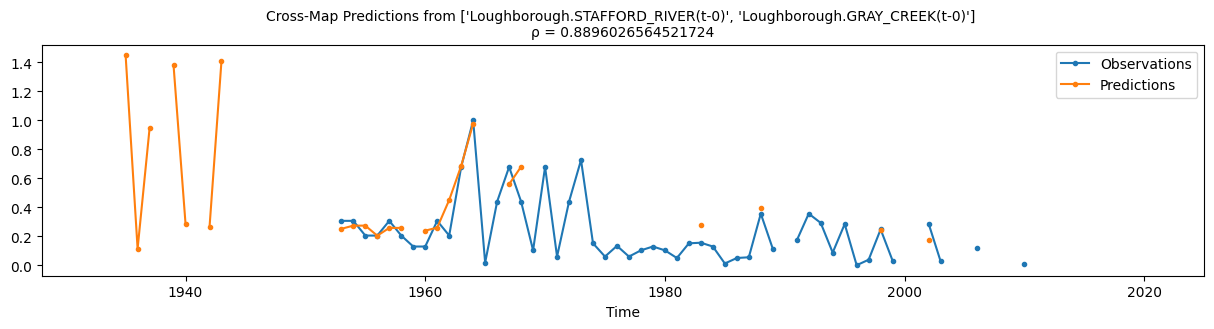

In [17]:
# Look at predictions from a single embedding
idx = 59
embedding = list(summary.loc[idx,'embedding'])
# embedding = list(summary[summary.n_pred>n_pred].reset_index(drop=True).loc[0,'embedding'])

xmap = compute_xmap_pair_smap(block_subset.reset_index(), embedding, target, lib, pred, Tp, theta, embedded, noTime=False) 
rho = xmap[3][['Observations', 'Predictions']].corr().iloc[0,1]

fig, ax = plt.subplots(figsize=(15,3))
xmap[3].plot(x='Time', y=['Observations', 'Predictions'], marker='.', ax=ax)
ax.set_title(f'Cross-Map Predictions from {embedding} \nρ = {rho}', fontsize=10)
ax.set_xlim(data['year'].min() - 1, data['year'].max() + 1)
plt.show()

In [113]:
## Fill gaps

def optimized_fill_gaps(data, target, embedding_results, k, self_weight):
    
    # Extract rho and sort embeddings
    all_embs = list(embedding_results.keys())

    # Filter out the embeddings that have predictions
    valid_embs = [emb for emb in all_embs if embedding_results[emb]['predictions'] is not None]
    rhos = np.array([embedding_results[e]['rho'] for e in valid_embs])

    # Create DataFrames containing all valid Predictions and Masks
    time_index = data.index
    num_rows = len(time_index)
    num_cols = len(valid_embs)

    preds_array = np.empty((num_rows, num_cols))
    masks_array = np.empty((num_rows, num_cols), dtype=bool)
    for col_idx, emb in enumerate(valid_embs):
        preds_array[:, col_idx] = embedding_results[emb]['predictions']['Predictions'].to_numpy()
        masks_array[:, col_idx] = embedding_results[emb]['pred_mask']['Mask'].to_numpy()

    pred_matrix = pd.DataFrame(preds_array, index=time_index, columns=valid_embs)
    mask_matrix = pd.DataFrame(masks_array, index=time_index, columns=valid_embs)

    # Clean predictions: set NaN or Masked-False to 0
    invalid_mask = (~mask_matrix) | (np.isnan(pred_matrix))
    pred_matrix[invalid_mask] = 0

    # Top k selection per row
    rho_matrix = np.tile(rhos, (len(time_index), 1))
    rho_matrix[invalid_mask] = -np.inf
    top_k_indices = np.argpartition(-rho_matrix, k - 1, axis=1)[:,:k]

    # Create weight mask
    final_mask = np.zeros_like(rho_matrix, dtype=bool)
    rows = np.arange(len(time_index))[:, None]
    final_mask[rows, top_k_indices] = True
    final_mask[invalid_mask] = False

    # Compute weights
    weighted_rhos = np.where(final_mask, rho_matrix, 0)
    weighted_rhos = np.clip(weighted_rhos, 0, None)

    row_sums = weighted_rhos.sum(axis=1, keepdims=True)
    weights = np.divide(weighted_rhos, row_sums, out=np.zeros_like(weighted_rhos), where=row_sums!=0)
    weights *= (1 - self_weight/100)
    
    # Final Estimate
    estimates = np.sum(pred_matrix * weights, axis=1)
    estimates = np.maximum(estimates, 0)
    estimated_series = pd.Series(estimates, index=time_index, name="Estimated_Values")
    
    # Fill Gaps
    filled_series = ts_data[target].copy()
    gap_mask = filled_series.isna()
    filled_series[gap_mask] = estimates[gap_mask]

    # Return both true and estimated values
    comparison_df = pd.DataFrame({
        f'{target} Observations': ts_data[target].copy(), # observations
        f'{target} Predictions (MVCM)': estimated_series, # all MVCM predictions
        f'{target} Filled (MVCM)': filled_series          # gap filled time series (original + MVCM in gaps)
    })
    
    return comparison_df

# Fill gaps in time series
filled_series = optimized_fill_gaps(
    data=ts_data,
    target=target,
    embedding_results=embedding_results,
    k=50,
    self_weight=0         # self_weight = 0 for gap filling
)

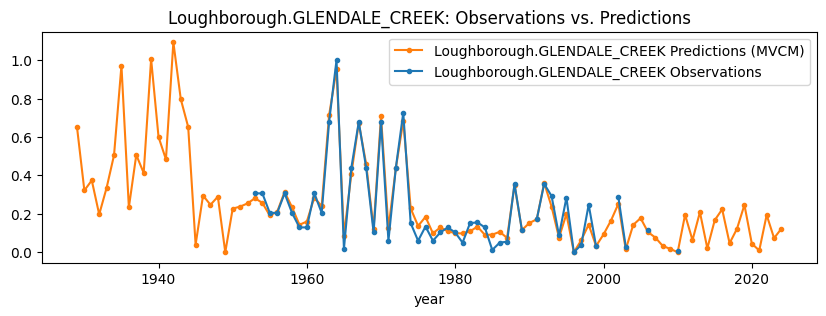

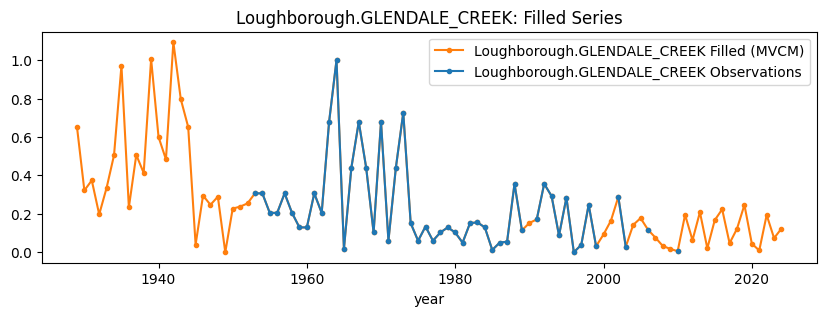

In [114]:
# Visualize MVCM observations vs. predictions
fig, ax = plt.subplots(figsize=(10,3))
filled_series.plot(ax=ax, y=[f'{target} Predictions (MVCM)', f'{target} Observations'], color=['tab:orange', 'tab:blue'], style='.-')
ax.set_title(f'{target}: Observations vs. Predictions')
plt.legend()
plt.show()

# Filled time series
fig, ax = plt.subplots(figsize=(10,3))
filled_series.plot(ax=ax, y=[f'{target} Filled (MVCM)', f'{target} Observations'], color=['tab:orange', 'tab:blue'], style='.-')
ax.set_title(f'{target}: Filled Series')
plt.legend()
plt.show()

## Optimizing MVCM Parameters

Optimize based on how well MVCM predicts the points we do have. I found that it works better to optimize theta "globally" (i.e. rather than finding the optimal theta for each individual embedding, use one theta across all embeddings). I found that the optimal "ensemble theta" is typically pretty high. A high theta value + a high k (number of embeddings) allows you to average the results of many highly localized models, so you get the benefit of being able to average over more models while also not losing too much of the range.

In [126]:
## Function for gap filling that takes a range of k's (more efficient for parameter optimization)

def optimize_k(data, target, embedding_results, k_list, self_weight):
    '''
    Code for gap filling using embedding results.
    Generates MVCM estimates for a list of k values.
    Returns a dictionary of {k: rho}, where rho is the correlation between observations and predictions.
    '''
    
    # Extract rho and sort embeddings
    all_embs = list(embedding_results.keys())

    # Filter out the embeddings that have predictions
    valid_embs = [emb for emb in all_embs if embedding_results[emb]['predictions'] is not None]
    rhos = np.array([embedding_results[e]['rho'] for e in valid_embs])

    # Create DataFrames containing all valid Predictions and Masks
    time_index = data.index
    num_rows = len(time_index)
    num_cols = len(valid_embs)

    preds_array = np.empty((num_rows, num_cols))
    masks_array = np.empty((num_rows, num_cols), dtype=bool)
    for col_idx, emb in enumerate(valid_embs):
        preds_array[:, col_idx] = embedding_results[emb]['predictions']['Predictions'].to_numpy()
        masks_array[:, col_idx] = embedding_results[emb]['pred_mask']['Mask'].to_numpy()

    pred_matrix = pd.DataFrame(preds_array, index=time_index, columns=valid_embs)
    mask_matrix = pd.DataFrame(masks_array, index=time_index, columns=valid_embs)

    # Clean predictions: set NaN or Masked-False to 0
    invalid_mask = (~mask_matrix) | (np.isnan(pred_matrix))
    pred_matrix[invalid_mask] = 0

    # Top k selection per row
    rho_matrix = np.tile(rhos, (len(time_index), 1))
    rho_matrix[invalid_mask] = -np.inf

    observations = ts_data[target].to_numpy()
    results_dict = {}

    # Loop over k's
    for k in k_list:
        # Cap k at the maximum available valid embeddings
        current_k = min(k, len(valid_embs))

        # Top k selection
        top_k_indices = np.argpartition(-rho_matrix, current_k - 1, axis=1)[:,:current_k]

        # Create weight mask
        final_mask = np.zeros_like(rho_matrix, dtype=bool)
        rows = np.arange(len(time_index))[:,None]
        final_mask[rows, top_k_indices] = True
        final_mask[invalid_mask] = False

        # Compute weights
        weighted_rhos = np.where(final_mask, rho_matrix, 0)
        weighted_rhos = np.clip(weighted_rhos, 0, None)

        row_sums = weighted_rhos.sum(axis=1, keepdims=True)
        weights = np.divide(weighted_rhos, row_sums, out=np.zeros_like(weighted_rhos), where=row_sums != 0)
        weights *= (1 - self_weight/100)
        
        # Calculate estimates
        estimates = np.sum(pred_matrix.values * weights, axis=1)
        estimates = np.maximum(estimates, 0)
        
        # Calculate correlation against true observations (ignoring NaNs)
        valid_idx = ~np.isnan(observations) & ~np.isnan(estimates)
        if np.sum(valid_idx) > 1:
            corr = np.corrcoef(observations[valid_idx], estimates[valid_idx])[0, 1]
        else:
            corr = np.nan
            
        results_dict[k] = corr

    return results_dict

In [121]:
# 1. Define parameter grids
theta_list = [1, 2, 5, 8, 10]
k_list = [5, 10, 20, 50, 75]

# Base S-map constants
Tp = 0
lib = f'1 {len(ts_data)}'
pred = f'1 {len(ts_data)}'
embedded = True
noTime = False
self_weight = 0

grid_results = []

# 2. Run Optimization Loop
for current_theta in theta_list:
    print(f"\n--- Evaluating Theta = {current_theta} ---")
    
    # Run heavy S-map calculation once per theta
    _, current_emb_results = get_xmap_results_smap(
        block=block_subset.reset_index(), 
        target=target, 
        embeddings=all_unique_embeddings, 
        Tp=Tp, 
        theta=current_theta, 
        lib=lib, 
        pred=pred, 
        embedded=embedded, 
        noTime=noTime, 
        progress_bar=True
    )
    
    # Run fast k evaluation for this theta    
    k_correlations = optimize_k(
        data=ts_data, 
        target=target, 
        embedding_results=current_emb_results, 
        k_list=k_list,
        self_weight=self_weight
    )
    
    # Save parameters and their scores
    for k, corr in k_correlations.items():
        grid_results.append({
            'theta': current_theta,
            'k': k,
            'Correlation': corr
        })

# 3. Create a clean Summary DataFrame
summary_df = pd.DataFrame(grid_results)

# Pivot into an easily readable matrix (Rows = Theta, Columns = K)
optimization_matrix = summary_df.pivot(index='theta', columns='k', values='Correlation')

print("\n--- Optimization Summary Matrix (Correlation Coefficient) ---")
display(optimization_matrix)


--- Evaluating Theta = 1 ---


Running S-map: 100%|██████████████████| 258532/258532 [01:56<00:00, 2217.43it/s]



--- Evaluating Theta = 2 ---


Running S-map: 100%|██████████████████| 258532/258532 [02:02<00:00, 2108.13it/s]



--- Evaluating Theta = 5 ---


...

Running S-map: 100%|██████████████████| 258532/258532 [01:45<00:00, 2446.88it/s]



--- Evaluating Theta = 10 ---


Running S-map: 100%|██████████████████| 258532/258532 [01:47<00:00, 2403.92it/s]



--- Optimization Summary Matrix (Correlation Coefficient) ---


k,5,10,20,50,75
theta,,,,,
1,0.936269,0.947895,0.942882,0.932998,0.929778
2,0.948825,0.962170,0.966434,0.960236,0.958162
5,0.955498,0.980350,0.981450,0.983054,0.982953
8,0.944842,0.969551,0.985701,0.985603,0.985253
10,0.514788,0.514788,0.514788,0.514789,0.514789


## Best MVCM Estimate (using optimal parameters)

Running S-map: 100%|██████████████████| 258532/258532 [02:02<00:00, 2106.60it/s]


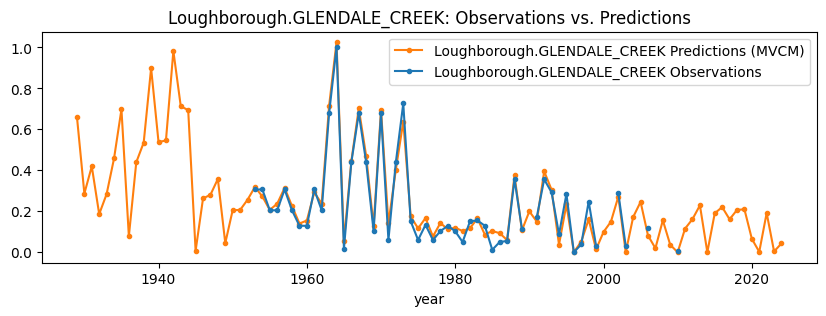

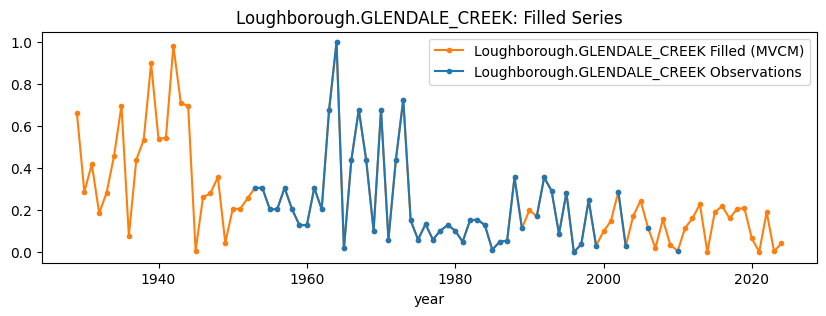

In [125]:
theta = 8
k = 20
Tp = 0
lib = f'1 {len(ts_data)}'
pred = f'1 {len(ts_data)}'
embedded = True
noTime = False

# Computing individual embeddings
summary, embedding_results = get_xmap_results_smap(block_subset.reset_index(), target, all_unique_embeddings, Tp, theta, lib, pred, embedded, 
                                                   noTime, progress_bar=True)

# Fill gaps in time series
print('filling gaps...')
filled_series = optimized_fill_gaps(
    data=ts_data,
    target=target,
    embedding_results=embedding_results,
    k=50,
    self_weight=0         # self_weight = 0 for gap filling
)

# Visualize MVCM observations vs. predictions
fig, ax = plt.subplots(figsize=(10,3))
filled_series.plot(ax=ax, y=[f'{target} Predictions (MVCM)', f'{target} Observations'], color=['tab:orange', 'tab:blue'], style='.-')
ax.set_title(f'{target}: Observations vs. Predictions')
plt.legend()
plt.show()

# Filled time series
fig, ax = plt.subplots(figsize=(10,3))
filled_series.plot(ax=ax, y=[f'{target} Filled (MVCM)', f'{target} Observations'], color=['tab:orange', 'tab:blue'], style='.-')
ax.set_title(f'{target}: Filled Series')
plt.legend()
plt.show()